# Deep Learning: Graph Machine Learning Hands-On (Embeddings, Spectral Methods, GNNs)

> **Who is this for:** a beginner who has read the theory notebook [`07_gnn.ipynb`](07_gnn.ipynb) and wants to build graph models from scratch, and BS/MS AI students revising spectral methods, node embeddings, GCN/GraphSAGE/GAT, link prediction and the WL test.
>
> **What you will learn**
> - How a graph becomes **matrices** (adjacency, degree, features) in NetworkX and PyTorch, on a synthetic **stochastic block model** and **Zachary's karate club**
> - **Classic node features** (degree, PageRank, clustering, centralities) and a logistic-regression baseline; PageRank by power iteration
> - **Spectral embedding / Laplacian eigenmaps** and spectral clustering
> - **DeepWalk / node2vec** random walks with a **skip-gram** model trained in PyTorch; t-SNE of the embeddings
> - **GCN from scratch** for semi-supervised node classification, plus **GraphSAGE** (mean aggregator) and single-head **GAT**
> - **Link prediction** with a leakage-free edge split, negative sampling and AUC; heuristics (common neighbours, Adamic-Adar) vs a GNN
> - **Graph classification** with sum/mean readout, and the **Weisfeiler-Lehman** test that bounds what message passing can see
> - **Over-smoothing** (accuracy vs depth) and **neighbour sampling** for big graphs; an optional PyTorch Geometric cell
>
> **Prerequisites:** [`07_gnn.ipynb`](07_gnn.ipynb) (formulas), [`00_AI_Fundamentals/dsa/07_graphs.ipynb`](../00_AI_Fundamentals/dsa/07_graphs.ipynb) (graph representations, BFS), [`14_Mathematics/discrete_math/03_graph_theory.ipynb`](../14_Mathematics/discrete_math/03_graph_theory.ipynb) (Laplacian, spectra), [`14_Mathematics/01_linear_algebra.ipynb`](../14_Mathematics/01_linear_algebra.ipynb) (eigenvectors), and [`00_start_here_pytorch_from_zero.ipynb`](00_start_here_pytorch_from_zero.ipynb).
>
> **Time needed:** about 3-4 hours.
>
> **Runs on:** CPU, no API key, no downloads (all graphs are synthetic or built into NetworkX). PyTorch Geometric is **optional**; the lesson runs without it.
>
> **Optional track:** this notebook is part of the **university-level fundamentals track**. We recommend it for BS/MS AI students and for interview prep. It is the hands-on companion to [`07_gnn.ipynb`](07_gnn.ipynb).

## Explained simply

A **graph** is a set of things (nodes) and the connections between them (edges): people and friendships, web pages and links, atoms and chemical bonds, products and "bought together". Ordinary machine learning looks at each example on its own; **graph machine learning** also uses the connections, because connected things tend to be alike ("tell me who your friends are and I will tell you who you are"). The main tool is **message passing**: every node collects information from its neighbours, mixes it with its own, and repeats; after two rounds, each node "knows" about its friends of friends. We will use this to label nodes when only a few labels are known, to predict missing links, and to classify whole graphs.

Everyday pictures: a **rumour spreading** through a school: after one round you know what your friends think; after two rounds you also know their friends' opinions. A **recommendation**: "people who bought this also bought..." is link prediction on a customer-product graph.

**A tiny example.** Four friends: Ali-Bea, Bea-Cem, Cem-Dan. Only Ali is labelled "likes football" (1) and Dan "does not" (0). Give the unknown people a neutral 0.5, then let everyone average their own value with their neighbours' values. Bea averages Ali, herself and Cem: $(1 + 0.5 + 0.5)/3 = 0.67$, so she leans towards football. Cem averages Bea, himself and Dan: $(0.5 + 0.5 + 0)/3 = 0.33$, so he leans towards no. That averaging is, in miniature, what a graph convolutional network does with learned weights.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Node embedding | a short list of numbers per node, similar for nodes in similar positions | friend suggestions, fraud rings in payment networks |
| Graph neural network (GNN) | each node repeatedly mixes its neighbours' information | molecule property prediction, traffic forecasting (Google Maps ETAs), recommender systems (PinSage at Pinterest) |
| Link prediction | guess which missing edges probably exist | "people you may know", drug-target interaction discovery, knowledge-graph completion |

## Contents

1. Setup: graphs as matrices (SBM and karate club)
2. Classic node features and a logistic-regression baseline
3. Spectral embedding and Laplacian eigenmaps
4. DeepWalk / node2vec random walks + skip-gram
5. GCN from scratch, GraphSAGE, GAT
6. Link prediction without leakage
7. Graph classification, readout, and the Weisfeiler-Lehman test
8. Over-smoothing, mini-batching and neighbour sampling; optional PyTorch Geometric
9. How this connects to modern AI
10. Recap, practice problems, further reading

## 1. Setup: graphs as matrices

> 💬 **In plain English:** a computer stores a graph as a table that says who is connected to whom (the adjacency matrix) plus a table of facts about each node (the feature matrix).

For $N$ nodes: the **adjacency matrix** $A\in\{0,1\}^{N\times N}$ with $A_{ij}=1$ if $i$ and $j$ are connected (symmetric for undirected graphs); the **degree matrix** $D = \operatorname{diag}(d_1..d_N)$ with $d_i = \sum_j A_{ij}$; and a **feature matrix** $X\in\mathbb R^{N\times F}$. Dense $A$ needs $O(N^2)$ memory; real graphs are stored sparsely ($O(N+E)$, e.g. an edge list `edge_index` of shape $2\times E$).

Two graphs:
- A **stochastic block model (SBM)**: 3 communities of 60 nodes; two nodes are linked with probability 0.12 inside a community and 0.01 across. Each node also has 16 **noisy features** weakly correlated with its community, so features alone are not enough and the graph has to help.
- **Zachary's karate club** (1977): 34 members of a university club that split into two factions ("Mr. Hi" and "Officer"); a classic benchmark that ships with NetworkX.

SBM: 180 nodes, 728 edges, mean degree 8.1, edges inside communities: 87%
Karate club: 34 nodes, 78 edges, factions [17 17]


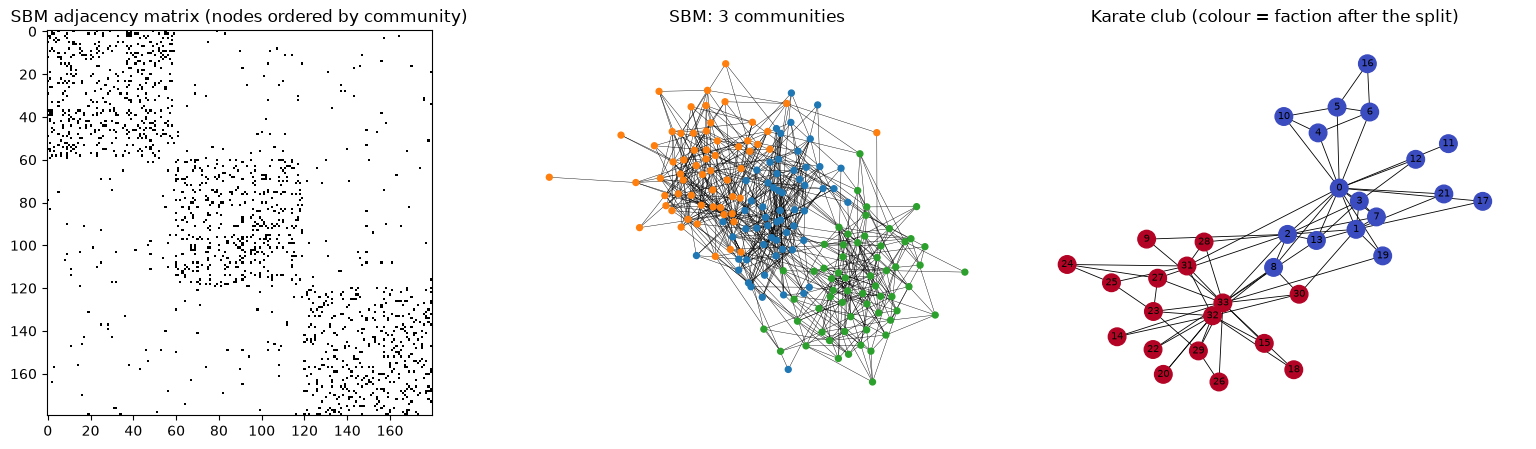

In [1]:
import math, time, random, itertools, copy                 # standard library
from collections import Counter
import numpy as np                                         # arrays
import pandas as pd                                        # tables
import matplotlib.pyplot as plt                            # plots
import networkx as nx                                      # graph data structures and classic algorithms
import torch, torch.nn as nn, torch.nn.functional as F    # GNNs
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, adjusted_rand_score
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

torch.set_num_threads(2)
SEED = 0
def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
seed_all()
pd.set_option("display.precision", 3)

# --- Stochastic block model with noisy node features
sizes, P = [60, 60, 60], [[0.12, 0.01, 0.01], [0.01, 0.12, 0.01], [0.01, 0.01, 0.12]]
G = nx.stochastic_block_model(sizes, P, seed=SEED)
y_sbm = np.array([G.nodes[v]["block"] for v in G.nodes])
N = G.number_of_nodes()
rng = np.random.default_rng(SEED)
class_means = rng.normal(0, 1, size=(3, 16))
X_sbm = 0.35 * class_means[y_sbm] + rng.normal(0, 1, size=(N, 16))      # weak signal + strong noise
A_sbm = torch.tensor(nx.to_numpy_array(G, nodelist=range(N)), dtype=torch.float32)
print(f"SBM: {N} nodes, {G.number_of_edges()} edges, mean degree {2 * G.number_of_edges() / N:.1f}, "
      f"edges inside communities: {np.mean([y_sbm[u] == y_sbm[v] for u, v in G.edges]):.0%}")

# --- Zachary's karate club
K = nx.karate_club_graph()
y_kc = np.array([0 if K.nodes[v]["club"] == "Mr. Hi" else 1 for v in K.nodes])
A_kc = torch.tensor(nx.to_numpy_array(K, nodelist=range(34), weight=None), dtype=torch.float32)
print(f"Karate club: {K.number_of_nodes()} nodes, {K.number_of_edges()} edges, factions {np.bincount(y_kc)}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].imshow(A_sbm, cmap="Greys", interpolation="nearest"); ax[0].set_title("SBM adjacency matrix (nodes ordered by community)")
pos_sbm = nx.spring_layout(G, seed=SEED)
nx.draw_networkx(G, pos_sbm, ax=ax[1], node_size=18, node_color=y_sbm, cmap="tab10", vmin=0, vmax=9, with_labels=False, width=0.3)
ax[1].set_title("SBM: 3 communities"); ax[1].axis("off")
pos_kc = nx.spring_layout(K, seed=3)
nx.draw_networkx(K, pos_kc, ax=ax[2], node_size=160, node_color=y_kc, cmap="coolwarm", font_size=7, width=0.6)
ax[2].set_title("Karate club (colour = faction after the split)"); ax[2].axis("off")
plt.tight_layout(); plt.show()

## 2. Classic node features and a baseline

> 💬 **In plain English:** before deep learning, people described each node with hand-made numbers: how many friends it has, how important its friends are, how tightly knit its friend group is.

| Feature | Definition | Intuition |
|---|---|---|
| **Degree** | $d_i = \sum_j A_{ij}$ | number of connections |
| **Clustering coefficient** | $\frac{\#\text{triangles through } i}{\binom{d_i}{2}}$ | are my friends friends with each other? |
| **PageRank** | stationary distribution of a random surfer: $r = \frac{1-\alpha}{N}\mathbf 1 + \alpha\, A^\top D^{-1} r$ | important if linked from important nodes |
| **Betweenness** | share of shortest paths that pass through $i$ | brokers / bridges |
| **Closeness** | $(N-1)/\sum_j \text{dist}(i,j)$ | how quickly $i$ reaches everyone |
| **Eigenvector centrality** | leading eigenvector of $A$ | similar to PageRank without teleport |

PageRank (Brin & Page, 1998) is computed by **power iteration**; with damping $\alpha = 0.85$ it converges geometrically, the error shrinking by a factor of about $\alpha$ per iteration.

In [2]:
def pagerank_power(G, alpha=0.85, tol=1e-12, max_iter=200):
    nodes = list(G.nodes); n = len(nodes)
    A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
    out_deg = A.sum(1)
    M = (A / out_deg[:, None]).T                          # column-stochastic transition matrix A^T D^-1
    r = np.full(n, 1 / n)
    for it in range(max_iter):
        r_new = (1 - alpha) / n + alpha * M @ r           # teleport + follow a random link
        if np.abs(r_new - r).sum() < tol:
            break
        r = r_new
    return dict(zip(nodes, r_new)), it + 1

pr, iters = pagerank_power(K)
pr_nx = nx.pagerank(K, alpha=0.85, weight=None, tol=1e-12)        # tighter tolerance than the default 1e-6
print(f"power iteration converged in {iters} iterations; max |ours - networkx| = {max(abs(pr[v] - pr_nx[v]) for v in K):.1e}")
print("top-5 PageRank in the karate club:", sorted(pr, key=pr.get, reverse=True)[:5], "(0 = Mr. Hi, 33 = the Officer)")

def classic_features(G):
    feats = {"degree": dict(G.degree()), "clustering": nx.clustering(G), "pagerank": nx.pagerank(G),
             "betweenness": nx.betweenness_centrality(G), "closeness": nx.closeness_centrality(G),
             "eigenvector": nx.eigenvector_centrality_numpy(G)}
    return pd.DataFrame(feats).loc[list(G.nodes)]

F_kc, F_sbm = classic_features(K), classic_features(G)
print(F_kc.head())

power iteration converged in 75 iterations; max |ours - networkx| = 1.0e-11
top-5 PageRank in the karate club: [33, 0, 32, 2, 1] (0 = Mr. Hi, 33 = the Officer)
   degree  clustering  pagerank  betweenness  closeness  eigenvector
0      16       0.150     0.089    4.376e-01      0.569        0.355
1       9       0.333     0.057    5.394e-02      0.485        0.266
2      10       0.244     0.063    1.437e-01      0.559        0.317
3       6       0.667     0.037    1.191e-02      0.465        0.211
4       3       0.667     0.021    6.313e-04      0.379        0.076


In [3]:
def few_label_split(y, per_class, seed=SEED):
    r = np.random.default_rng(seed)
    train = np.concatenate([r.choice(np.where(y == c)[0], per_class, replace=False) for c in np.unique(y)])
    test = np.setdiff1d(np.arange(len(y)), train)
    return train, test

def logreg_accuracy(Z, y, train, test):
    Z = (Z - Z.mean(0)) / (Z.std(0) + 1e-9)
    clf = LogisticRegression(max_iter=2000).fit(Z[train], y[train])
    return clf.score(Z[test], y[test])

tr_kc, te_kc = few_label_split(y_kc, 4)
tr_sbm, te_sbm = few_label_split(y_sbm, 5)
baseline = {
    "karate: classic features": logreg_accuracy(F_kc.values, y_kc, tr_kc, te_kc),
    "SBM: classic features": logreg_accuracy(F_sbm.values, y_sbm, tr_sbm, te_sbm),
    "SBM: node features X only": logreg_accuracy(X_sbm, y_sbm, tr_sbm, te_sbm),
}
print(f"labelled nodes: karate {len(tr_kc)} of 34, SBM {len(tr_sbm)} of {N}")
print(pd.Series(baseline, name="test accuracy"))

labelled nodes: karate 8 of 34, SBM 15 of 180
karate: classic features     0.538
SBM: classic features        0.612
SBM: node features X only    0.467
Name: test accuracy, dtype: float64


**What just happened?** Our power-iteration PageRank matches NetworkX (run with the same tight tolerance) to many decimal places, and the two leaders of the factions (nodes 33 and 0) are the two most central members. As a basis for classifying *communities*, though, classic features are weak: in the karate club they are at chance level, because both factions contain a leader, a few lieutenants and many peripheral members, i.e. the same mix of structural roles. On the SBM they do somewhat better than the 33% chance level, mainly because some centralities (eigenvector centrality in particular) concentrate on the most densely connected community; degree and clustering alone cannot tell three statistically identical communities apart. The noisy features alone are also weak. **Structural roles ≠ community membership**; to find communities we need methods that look at *who is connected to whom*.

## 3. Spectral embedding and Laplacian eigenmaps

> 💬 **In plain English:** imagine the graph as a system of springs. The slowest ways it can wobble move whole communities together; those "vibration patterns" (eigenvectors) become coordinates in which communities separate.

The **graph Laplacian** $L = D - A$ satisfies $x^\top L x = \sum_{(i,j)\in E}(x_i - x_j)^2$, so eigenvectors with **small** eigenvalues are functions that change little across edges, i.e. are roughly constant on densely connected groups. The **symmetric normalised Laplacian** $L_{sym} = I - D^{-1/2}AD^{-1/2}$ has eigenvalues in $[0, 2]$; the number of (near-)zero eigenvalues equals the number of (nearly) disconnected components. **Laplacian eigenmaps** (Belkin & Niyogi, 2003) embed node $i$ as the $i$-th row of the first $k$ non-trivial eigenvectors; **spectral clustering** runs k-means on that embedding. For the deeper theory see [`14_Mathematics/discrete_math/03_graph_theory.ipynb`](../14_Mathematics/discrete_math/03_graph_theory.ipynb).

smallest 6 eigenvalues of L_sym: [-0.     0.121  0.158  0.384  0.4    0.421]
spectral clustering vs true communities: adjusted Rand index = 0.966
assert L_sym matches networkx: True
karate club: Fiedler-vector sign agrees with the real faction for 94% of members (no labels used)


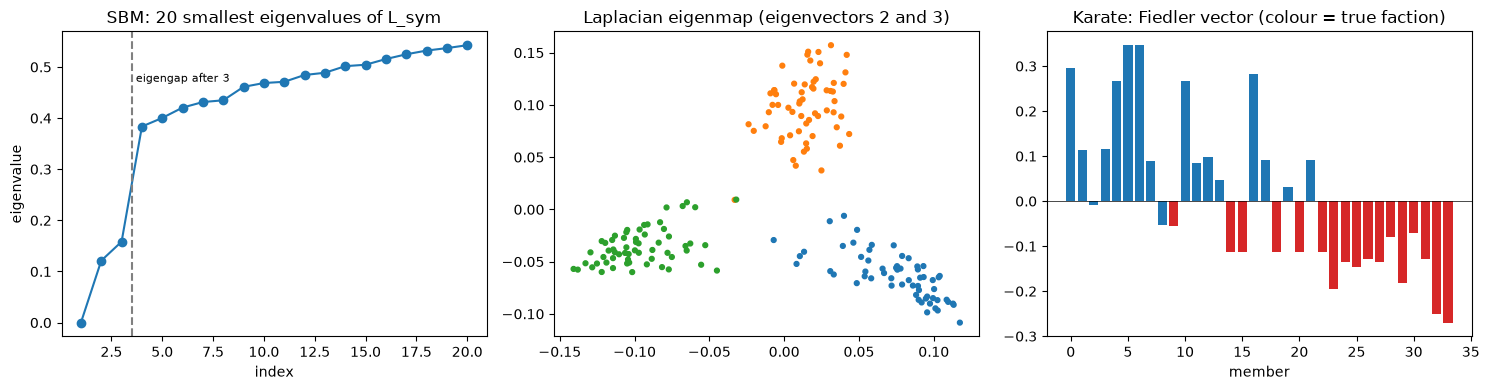

In [4]:
def normalized_laplacian(A):
    d = A.sum(1)
    d_inv_sqrt = np.where(d > 0, 1 / np.sqrt(d), 0)
    return np.eye(len(A)) - d_inv_sqrt[:, None] * A * d_inv_sqrt[None, :]

A_np = A_sbm.numpy()
evals, evecs = np.linalg.eigh(normalized_laplacian(A_np))            # ascending eigenvalues
emb_spec = evecs[:, 1:3]                                              # skip the trivial first eigenvector
emb_spec_rownorm = evecs[:, :3] / np.linalg.norm(evecs[:, :3], axis=1, keepdims=True)   # Ng-Jordan-Weiss normalisation
km = KMeans(3, n_init=10, random_state=SEED).fit(emb_spec_rownorm)
print("smallest 6 eigenvalues of L_sym:", evals[:6].round(3))
print("spectral clustering vs true communities: adjusted Rand index =", round(adjusted_rand_score(y_sbm, km.labels_), 3))
print("assert L_sym matches networkx:", np.allclose(normalized_laplacian(A_np), nx.normalized_laplacian_matrix(G, nodelist=range(N)).toarray()))

# Karate club: the sign of the Fiedler vector (2nd eigenvector) splits the club in two
ev_k, evec_k = np.linalg.eigh(normalized_laplacian(A_kc.numpy()))
fiedler = evec_k[:, 1]
split = (fiedler > 0).astype(int)
acc_fiedler = max((split == y_kc).mean(), (split != y_kc).mean())      # the sign is arbitrary
print(f"karate club: Fiedler-vector sign agrees with the real faction for {acc_fiedler:.0%} of members (no labels used)")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(range(1, 21), evals[:20], "o-"); ax[0].set_xlabel("index"); ax[0].set_ylabel("eigenvalue"); ax[0].set_title("SBM: 20 smallest eigenvalues of L_sym")
ax[0].axvline(3.5, ls="--", c="gray"); ax[0].text(3.7, evals[10], "eigengap after 3", fontsize=8)
ax[1].scatter(emb_spec[:, 0], emb_spec[:, 1], c=y_sbm, cmap="tab10", vmin=0, vmax=9, s=12); ax[1].set_title("Laplacian eigenmap (eigenvectors 2 and 3)")
ax[2].bar(range(34), fiedler, color=["tab:blue" if c == 0 else "tab:red" for c in y_kc]); ax[2].axhline(0, c="k", lw=0.5)
ax[2].set_title("Karate: Fiedler vector (colour = true faction)"); ax[2].set_xlabel("member")
plt.tight_layout(); plt.show()

**What just happened?** The SBM's normalised Laplacian has **3 small eigenvalues followed by a jump** (the *eigengap*), revealing 3 communities without any labels; spectral clustering recovers them almost perfectly (adjusted Rand index near 1). In the karate club, simply taking the sign of the **Fiedler vector** predicts the real-world split for the large majority of members, which is the classic demonstration that the split followed the network's structure.

**Complexity:** a full eigendecomposition is $O(N^3)$; for large sparse graphs we need only $k$ eigenvectors, computed by Lanczos/ARPACK in roughly $O(k\,E)$ per iteration. Spectral embeddings are **transductive**: a new node needs a new decomposition.

## 4. DeepWalk / node2vec: random walks + skip-gram

> 💬 **In plain English:** walk randomly around the graph and write down the nodes you visit, like sentences made of node names. Nodes that often appear close together in those "sentences" get similar vectors, exactly as word2vec does for words.

**DeepWalk** (Perozzi et al., 2014): generate truncated uniform random walks, then train **skip-gram** (word2vec) on them. **node2vec** (Grover & Leskovec, 2016) biases the walk with two parameters. Having just moved from $t$ to $v$, the unnormalised probability of moving to a neighbour $x$ of $v$ is

| case | weight |
|---|---|
| $x = t$ (go back) | $1/p$ |
| $x$ is also a neighbour of $t$ (stay close) | $1$ |
| otherwise (move away) | $1/q$ |

Small $q$ favours outward, DFS-like exploration (captures communities / homophily); large $q$ keeps the walk local, BFS-like (captures structural roles). $p=q=1$ is DeepWalk.

**Skip-gram with negative sampling (SGNS):** for each (centre $u$, context $v$) pair within a window, maximise $\log\sigma(z_u^\top z'_v) + \sum_{n=1}^{k}\log\sigma(-z_u^\top z'_{n})$ with $k$ negatives drawn from the (degree$^{0.75}$) noise distribution.

3 embeddings trained in 9.4s; example walk: [146, 175, 147, 175, 148, 144, 162, 164, 162, 176]


                       ARI of k-means (no labels)  \
DeepWalk (p=1, q=1)                         0.950   
node2vec (p=1, q=0.5)                       0.967   
node2vec (p=1, q=2)                         0.950   

                       log-reg accuracy (15 labels)  
DeepWalk (p=1, q=1)                           0.927  
node2vec (p=1, q=0.5)                         0.903  
node2vec (p=1, q=2)                           0.952  


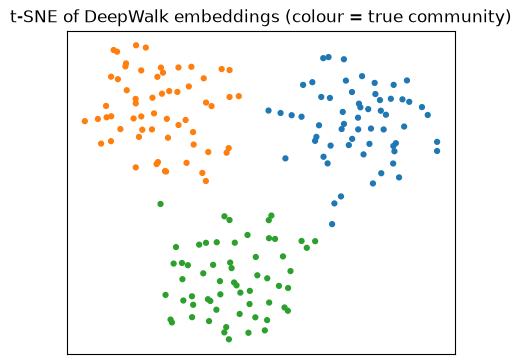

In [5]:
def node2vec_walks(G, num_walks=10, length=20, p=1.0, q=1.0, seed=SEED):
    r = np.random.default_rng(seed)
    nbrs = {v: list(G.neighbors(v)) for v in G.nodes}
    walks = []
    for _ in range(num_walks):
        for start in r.permutation(list(G.nodes)):
            walk = [int(start)]
            while len(walk) < length:
                cur = walk[-1]
                if not nbrs[cur]:
                    break
                if len(walk) == 1:
                    walk.append(int(r.choice(nbrs[cur]))); continue
                prev = walk[-2]
                w = np.array([1 / p if x == prev else (1.0 if G.has_edge(x, prev) else 1 / q) for x in nbrs[cur]])
                walk.append(int(nbrs[cur][r.choice(len(w), p=w / w.sum())]))
            walks.append(walk)
    return walks


def skipgram_pairs(walks, window=3):
    pairs = [(w[i], w[j]) for w in walks for i in range(len(w))
             for j in range(max(0, i - window), min(len(w), i + window + 1)) if i != j]
    return torch.tensor(pairs)


def train_sgns(pairs, n_nodes, degrees, dim=16, neg=5, epochs=3, batch=1024, seed=SEED):
    seed_all(seed)
    emb_in, emb_out = nn.Embedding(n_nodes, dim), nn.Embedding(n_nodes, dim)
    nn.init.normal_(emb_in.weight, std=0.1); nn.init.zeros_(emb_out.weight)
    noise = torch.tensor(degrees, dtype=torch.float) ** 0.75                  # word2vec's unigram^0.75
    opt = torch.optim.Adam(list(emb_in.parameters()) + list(emb_out.parameters()), lr=0.01)
    for _ in range(epochs):
        for b in pairs[torch.randperm(len(pairs))].split(batch):
            u, v = b[:, 0], b[:, 1]
            negs = torch.multinomial(noise, len(b) * neg, replacement=True).view(len(b), neg)
            zu = emb_in(u)
            pos = F.logsigmoid((zu * emb_out(v)).sum(-1))
            negv = F.logsigmoid(-(zu[:, None] * emb_out(negs)).sum(-1)).sum(-1)
            loss = -(pos + negv).mean()
            opt.zero_grad(); loss.backward(); opt.step()
    return emb_in.weight.detach().numpy()

deg_sbm = [G.degree(v) for v in range(N)]
emb = {}
t0 = time.perf_counter()
for name, p, q in [("DeepWalk (p=1, q=1)", 1, 1), ("node2vec (p=1, q=0.5)", 1, 0.5), ("node2vec (p=1, q=2)", 1, 2)]:
    walks = node2vec_walks(G, p=p, q=q)
    emb[name] = train_sgns(skipgram_pairs(walks), N, deg_sbm)
print(f"3 embeddings trained in {time.perf_counter() - t0:.1f}s; example walk: {walks[0][:10]}")

rows = {}
for name, Z in emb.items():
    km = KMeans(3, n_init=10, random_state=SEED).fit(Z)
    rows[name] = {"ARI of k-means (no labels)": adjusted_rand_score(y_sbm, km.labels_),
                  "log-reg accuracy (15 labels)": logreg_accuracy(Z, y_sbm, tr_sbm, te_sbm)}
print(pd.DataFrame(rows).T)

Z2 = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(emb["DeepWalk (p=1, q=1)"])
plt.figure(figsize=(5, 4.2)); plt.scatter(Z2[:, 0], Z2[:, 1], c=y_sbm, cmap="tab10", vmin=0, vmax=9, s=12)
plt.title("t-SNE of DeepWalk embeddings (colour = true community)"); plt.xticks([]); plt.yticks([]); plt.show()

**What just happened?** Without ever seeing a label, random walks + skip-gram place nodes of the same community close together: k-means on the 16-dimensional embeddings recovers the communities, a logistic regression on 15 labelled nodes classifies the rest accurately, and t-SNE shows three clean clusters. On this homophilous graph all three walk settings work; the $p, q$ knobs matter more on graphs where structural roles (hubs, bridges, leaves) are what you need.

**Complexity:** walks cost $O(r\cdot N\cdot \ell)$ for $r$ walks of length $\ell$ per node (node2vec adds a neighbour check per step); SGNS costs $O(\#\text{pairs}\cdot k\cdot d)$ per epoch. Like spectral methods, DeepWalk/node2vec are **transductive** and ignore node features.

> 🎓 **Exam / interview tip:** DeepWalk with a window of size $T$ implicitly factorises a matrix built from $\sum_{r=1}^{T}(D^{-1}A)^r$ (Qiu et al., 2018), so random-walk embeddings and spectral embeddings are close relatives.

## 5. Graph neural networks from scratch

> 💬 **In plain English:** a GNN layer lets every node average (with learned weights) the vectors of its neighbours and itself; stacking two layers mixes in friends-of-friends. Only a few nodes need labels, because information flows along the edges to the rest.

### 5.1 GCN (Kipf & Welling, 2017)

Add self-loops $\tilde A = A + I$, $\tilde D = \operatorname{diag}(\tilde A\mathbf 1)$, and normalise symmetrically: $\hat A = \tilde D^{-1/2}\tilde A\tilde D^{-1/2}$. A two-layer GCN is

$$Z = \operatorname{softmax}\big(\hat A\ \operatorname{ReLU}(\hat A X W^{(0)})\ W^{(1)}\big).$$

Per node, one layer is message passing: $h_i' = \sigma\Big(\sum_{j\in\mathcal N(i)\cup\{i\}} \frac{1}{\sqrt{\tilde d_i\tilde d_j}}\, W h_j\Big)$. **Semi-supervised training:** the cross-entropy is computed only on the labelled nodes, but the forward pass uses the whole graph, so unlabelled nodes shape every prediction.

### 5.2 GraphSAGE (Hamilton et al., 2017), mean aggregator

$h_i' = \sigma\big(W_{self}\,h_i + W_{neigh}\cdot\operatorname{mean}_{j\in\mathcal N(i)} h_j\big)$: the node's own vector is kept separate from the neighbourhood summary, and the aggregator works on sampled neighbourhoods (Section 8), which makes it **inductive** (works for new nodes).

### 5.3 GAT (Veličković et al., 2018), one head

Learned attention weights replace the fixed $1/\sqrt{\tilde d_i\tilde d_j}$:
$e_{ij} = \operatorname{LeakyReLU}\big(a^\top[Wh_i\,\Vert\,Wh_j]\big)$, $\alpha_{ij} = \operatorname{softmax}_{j\in\mathcal N(i)\cup\{i\}}(e_{ij})$, $h_i' = \sigma\big(\sum_j\alpha_{ij}Wh_j\big)$.

In [6]:
def gcn_norm(A):
    A_tilde = A + torch.eye(len(A))                          # self-loops
    d = A_tilde.sum(1)
    return A_tilde / torch.sqrt(d[:, None] * d[None, :])    # D^-1/2 (A + I) D^-1/2

# Check the matrix form against the per-node message-passing sum on the karate club
A_hat_kc = gcn_norm(A_kc)
Xc = torch.randn(34, 5)
loop = torch.stack([sum(Xc[j] / math.sqrt((K.degree(i) + 1) * (K.degree(j) + 1)) for j in list(K.neighbors(i)) + [i])
                    for i in range(34)])
print("max |A_hat X - message passing loop| =", (A_hat_kc @ Xc - loop).abs().max().item())


class GCN(nn.Module):
    def __init__(self, d_in, d_hidden, d_out, n_layers=2, dropout=0.5):
        super().__init__()
        dims = [d_in] + [d_hidden] * (n_layers - 1) + [d_out]
        self.lins = nn.ModuleList([nn.Linear(a, b) for a, b in zip(dims[:-1], dims[1:])])
        self.dropout = dropout

    def forward(self, X, A_hat):
        h = X
        for k, lin in enumerate(self.lins):
            h = F.dropout(h, self.dropout, self.training)
            h = A_hat @ lin(h)                                # transform, then propagate
            if k < len(self.lins) - 1:
                h = F.relu(h)
        return h


class SAGE(nn.Module):
    def __init__(self, d_in, d_hidden, d_out, dropout=0.5):
        super().__init__()
        self.self1, self.neigh1 = nn.Linear(d_in, d_hidden), nn.Linear(d_in, d_hidden, bias=False)
        self.self2, self.neigh2 = nn.Linear(d_hidden, d_out), nn.Linear(d_hidden, d_out, bias=False)
        self.dropout = dropout

    def forward(self, X, A_mean):                             # A_mean = D^-1 A (row-normalised, no self-loops)
        h = F.dropout(X, self.dropout, self.training)
        h = F.relu(self.self1(h) + self.neigh1(A_mean @ h))
        h = F.dropout(h, self.dropout, self.training)
        return self.self2(h) + self.neigh2(A_mean @ h)


class GATLayer(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.W = nn.Linear(d_in, d_out, bias=False)
        self.a_dst, self.a_src = nn.Parameter(torch.randn(d_out) * 0.1), nn.Parameter(torch.randn(d_out) * 0.1)

    def forward(self, H, mask):                               # mask: (N, N) bool, True where j is a neighbour of i (or i itself)
        Wh = self.W(H)
        e = F.leaky_relu((Wh @ self.a_dst)[:, None] + (Wh @ self.a_src)[None, :], 0.2)   # a^T [W h_i || W h_j]
        alpha = e.masked_fill(~mask, float("-inf")).softmax(dim=1)                        # normalise over neighbours
        self.alpha = alpha.detach()
        return alpha @ Wh


class GAT(nn.Module):
    def __init__(self, d_in, d_hidden, d_out, dropout=0.5):
        super().__init__()
        self.l1, self.l2, self.dropout = GATLayer(d_in, d_hidden), GATLayer(d_hidden, d_out), dropout

    def forward(self, X, mask):
        h = F.elu(self.l1(F.dropout(X, self.dropout, self.training), mask))
        return self.l2(F.dropout(h, self.dropout, self.training), mask)


class MLP(nn.Module):                                         # ignores the graph: the feature-only baseline
    def __init__(self, d_in, d_hidden, d_out, dropout=0.5):
        super().__init__()
        self.net = nn.Sequential(nn.Dropout(dropout), nn.Linear(d_in, d_hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d_hidden, d_out))

    def forward(self, X, _):
        return self.net(X)


def train_node_classifier(model, X, graph_input, y, train_idx, test_idx, epochs=200, lr=0.01, wd=5e-4, seed=SEED):
    seed_all(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    y_t = torch.tensor(y)
    for _ in range(epochs):
        model.train()
        loss = F.cross_entropy(model(X, graph_input)[train_idx], y_t[train_idx])   # loss on LABELLED nodes only
        opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        pred = model(X, graph_input).argmax(1)
    return (pred[test_idx] == y_t[test_idx]).float().mean().item()

max |A_hat X - message passing loop| = 1.1920928955078125e-07


In [7]:
X_t = torch.tensor(X_sbm, dtype=torch.float32)
A_hat = gcn_norm(A_sbm)
A_mean = A_sbm / A_sbm.sum(1, keepdim=True).clamp(min=1)
mask = (A_sbm + torch.eye(N)) > 0
results = {}
for name, make, ginput in [("MLP (features only)", lambda: MLP(16, 32, 3), None),
                           ("GCN", lambda: GCN(16, 32, 3), A_hat),
                           ("GraphSAGE-mean", lambda: SAGE(16, 32, 3), A_mean),
                           ("GAT (1 head)", lambda: GAT(16, 32, 3), mask)]:
    accs = []
    for split_seed in range(5):                                    # 5 random choices of the 15 labelled nodes
        tr, te = few_label_split(y_sbm, 5, seed=split_seed)
        seed_all(split_seed)
        accs.append(train_node_classifier(make(), X_t, ginput, y_sbm, torch.tensor(tr), torch.tensor(te), seed=split_seed))
    results[name] = {"mean test accuracy": np.mean(accs), "std": np.std(accs)}
print("SBM, 5 labelled nodes per class, 5 random label splits:")
print(pd.DataFrame(results).T)

SBM, 5 labelled nodes per class, 5 random label splits:
                     mean test accuracy    std
MLP (features only)               0.475  0.036
GCN                               0.988  0.005
GraphSAGE-mean                    0.947  0.032
GAT (1 head)                      0.953  0.032


**What just happened?** The matrix form $\hat AX$ equals the explicit per-node message-passing sum (difference at float round-off). On the SBM, the MLP sees only the noisy features of each node and does poorly; every GNN does far better because it averages the features over a node's neighbourhood, which is mostly the same community, so the noise cancels while the community signal adds up. GCN is the best here, with GraphSAGE and GAT a few points behind and more variable across label splits: with only 15 labels, the extra parameters of GraphSAGE (separate self and neighbour weights) and GAT (attention) are harder to fit. Their advantages show on graphs with skewed degrees, neighbours of varying relevance, or new unseen nodes.

### 5.4 Karate club with only 2 labels

The classic demonstration: features are just one-hot node IDs ($X = I$, so the model knows nothing but the graph), and only the two leaders, nodes 0 and 33, are labelled.

GCN with 2 labelled nodes: accuracy on the other 32 members = 0.969
misclassified members: [8]


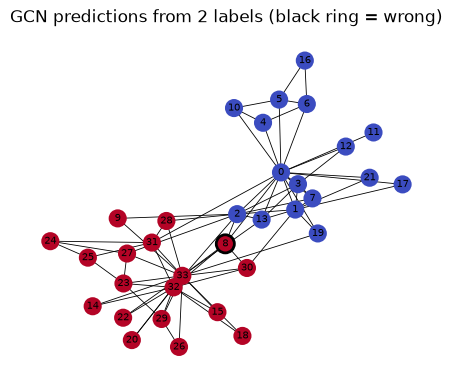

In [8]:
seed_all()
gcn_kc = GCN(34, 16, 2, dropout=0.0)
train_idx, test_idx = torch.tensor([0, 33]), torch.tensor([i for i in range(34) if i not in (0, 33)])
acc_kc = train_node_classifier(gcn_kc, torch.eye(34), A_hat_kc, y_kc, train_idx, test_idx, epochs=100)
with torch.no_grad():
    pred_kc = gcn_kc(torch.eye(34), A_hat_kc).argmax(1).numpy()
print(f"GCN with 2 labelled nodes: accuracy on the other 32 members = {acc_kc:.3f}")
wrong = [i for i in range(34) if pred_kc[i] != y_kc[i]]
print("misclassified members:", wrong)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
nx.draw_networkx(K, pos_kc, ax=ax, node_size=170, node_color=pred_kc, cmap="coolwarm", font_size=7, width=0.6,
                 edgecolors=["k" if i in wrong else "none" for i in range(34)], linewidths=2)
ax.set_title("GCN predictions from 2 labels (black ring = wrong)"); ax.axis("off"); plt.show()

**What just happened?** Knowing only the graph and two labels, the GCN assigns 31 of the other 32 members to the correct faction. The one mistake is member 8 (member 9 in Zachary's 1-based numbering), who has strong ties to both leaders; Zachary's own network-flow analysis in 1977 also placed this member in the wrong faction.

**Complexity of one GCN layer:** $O(E\cdot d + N\cdot d\cdot d')$ with sparse $\hat A$ (we used a dense matrix, $O(N^2 d)$, fine for small graphs). GAT costs a little more ($O(E\cdot d')$ extra for attention scores).

## 6. Link prediction without leakage

> 💬 **In plain English:** hide some real connections, then ask the model to rank the hidden ones above random pairs of nodes that are not connected. The model must never see the hidden edges, not even indirectly.

**Protocol.**
1. Remove 15% of the edges as **test positives**; the remaining edges form the **training graph**. All features, walks, heuristics and message passing may use **only the training graph**.
2. Sample the same number of **negatives**: node pairs that are not edges of the *original* graph.
3. Score every test pair; report **ROC-AUC** (probability that a random positive outranks a random negative; 0.5 = chance).

**Heuristics** for a pair $(u, v)$ with neighbour sets $\Gamma(\cdot)$:

| Heuristic | Score | Idea |
|---|---|---|
| Common neighbours | $|\Gamma(u)\cap\Gamma(v)|$ | friends of friends become friends (triadic closure) |
| Jaccard | $\frac{|\Gamma(u)\cap\Gamma(v)|}{|\Gamma(u)\cup\Gamma(v)|}$ | normalised overlap |
| Adamic-Adar | $\sum_{w\in\Gamma(u)\cap\Gamma(v)}\frac{1}{\log|\Gamma(w)|}$ | a shared friend with few friends counts more |
| Preferential attachment | $|\Gamma(u)|\cdot|\Gamma(v)|$ | popular nodes get more links |

**GNN approach (graph auto-encoder, Kipf & Welling 2016):** a GCN encoder on the training graph gives embeddings $z_i$; score a pair by $\sigma(z_u^\top z_v)$; train with binary cross-entropy on training edges vs freshly sampled negative pairs.

In [9]:
G_lp = nx.stochastic_block_model([75] * 4, [[0.15 if i == j else 0.01 for j in range(4)] for i in range(4)], seed=1)
N_lp = G_lp.number_of_nodes()
r = np.random.default_rng(1)
edges = np.array(list(G_lp.edges()))
perm = r.permutation(len(edges)); n_test = int(0.15 * len(edges))
test_pos, train_pos = edges[perm[:n_test]], edges[perm[n_test:]]

G_train = nx.Graph(); G_train.add_nodes_from(G_lp.nodes); G_train.add_edges_from(map(tuple, train_pos))
all_edges = set(map(tuple, edges)) | set((v, u) for u, v in edges)
neg = set()
while len(neg) < n_test:                                          # negatives: pairs that are not edges in the FULL graph
    u, v = r.integers(0, N_lp, 2)
    if u != v and (u, v) not in all_edges and (min(u, v), max(u, v)) not in neg:
        neg.add((min(u, v), max(u, v)))
test_neg = np.array(sorted(neg))
test_pairs = np.vstack([test_pos, test_neg]); test_labels = np.r_[np.ones(n_test), np.zeros(n_test)]
print(f"{len(edges)} edges -> {len(train_pos)} training edges, {n_test} test positives, {n_test} test negatives")

def heuristic_scores(graph, pairs):
    P = [tuple(map(int, p)) for p in pairs]
    return {"common neighbours": [len(list(nx.common_neighbors(graph, u, v))) for u, v in P],
            "Jaccard": [s for _, _, s in nx.jaccard_coefficient(graph, P)],
            "Adamic-Adar": [s for _, _, s in nx.adamic_adar_index(graph, P)],
            "preferential attachment": [s for _, _, s in nx.preferential_attachment(graph, P)]}

lp_rows = {}
for name, s in heuristic_scores(G_train, test_pairs).items():
    lp_rows[name] = {"AUC (training graph only)": roc_auc_score(test_labels, s)}
for name, s in heuristic_scores(G_lp, test_pairs).items():
    lp_rows[name]["AUC (LEAKY: full graph)"] = roc_auc_score(test_labels, s)

2000 edges -> 1700 training edges, 300 test positives, 300 test negatives


In [10]:
def train_gae(graph_edges, n_nodes, epochs=200, dim=32, seed=SEED):
    seed_all(seed)
    A = torch.zeros(n_nodes, n_nodes)
    A[graph_edges[:, 0], graph_edges[:, 1]] = 1; A[graph_edges[:, 1], graph_edges[:, 0]] = 1
    A_hat_lp = gcn_norm(A)
    enc = GCN(n_nodes, 64, dim, dropout=0.0)                     # X = I: one learnable vector per node
    opt = torch.optim.Adam(enc.parameters(), lr=0.01)
    pos = torch.tensor(graph_edges)
    for _ in range(epochs):
        z = enc(torch.eye(n_nodes), A_hat_lp)
        neg_s = torch.randint(0, n_nodes, pos.shape)                 # fresh random negatives every epoch
        pos_logit = (z[pos[:, 0]] * z[pos[:, 1]]).sum(1)
        neg_logit = (z[neg_s[:, 0]] * z[neg_s[:, 1]]).sum(1)
        loss = F.binary_cross_entropy_with_logits(pos_logit, torch.ones_like(pos_logit)) + \
               F.binary_cross_entropy_with_logits(neg_logit, torch.zeros_like(neg_logit))
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return enc(torch.eye(n_nodes), A_hat_lp)

def pair_scores(z, pairs):
    p = torch.tensor(pairs)
    return (z[p[:, 0]] * z[p[:, 1]]).sum(1).numpy()

t0 = time.perf_counter()
z_ok = train_gae(train_pos, N_lp)                                 # message passing on the training graph
z_leak = train_gae(edges, N_lp)                                   # BUG: test edges inside the message-passing graph
lp_rows["GCN auto-encoder"] = {"AUC (training graph only)": roc_auc_score(test_labels, pair_scores(z_ok, test_pairs)),
                               "AUC (LEAKY: full graph)": roc_auc_score(test_labels, pair_scores(z_leak, test_pairs))}
print(f"GAEs trained in {time.perf_counter() - t0:.1f}s")
print(pd.DataFrame(lp_rows).T)

GAEs trained in 1.6s
                         AUC (training graph only)  AUC (LEAKY: full graph)
common neighbours                            0.678                    0.711
Jaccard                                      0.681                    0.708
Adamic-Adar                                  0.673                    0.710
preferential attachment                      0.482                    0.589
GCN auto-encoder                             0.834                    0.895


**What just happened?** On the honest split, the common-neighbour family reaches an AUC of about 0.68: clearly better than chance, but limited, because in a sparse random graph many true links have no common neighbour at all, so they tie with most negatives at a score of 0. Preferential attachment is at chance level (degrees carry no community information here). The GCN auto-encoder does clearly better (about 0.83) because its embeddings capture community membership, which the heuristics can only see through shared neighbours.

The **leaky** column shows what happens when the test edges are left in the graph used for features or message passing: every method looks better. Preferential attachment rises from chance to about 0.59 simply because each hidden edge adds 1 to both endpoint degrees, and the GNN, which now sees the hidden edges through message passing and is even trained to reconstruct them, gains about 6 points. None of those gains would survive on genuinely unknown links.

> ⚠️ **Common mistake:** splitting edges for link prediction *after* computing node embeddings, PageRank, or a GNN on the full graph. Always split first; then compute everything from the training graph only. For temporal graphs, split by time (train on the past, test on future links).

## 7. Graph classification, readout and the Weisfeiler-Lehman test

> 💬 **In plain English:** to label a whole graph (e.g. "is this molecule toxic?"), run message passing on its nodes and then **pool** all node vectors into one graph vector. Whether you *sum* or *average* matters more than you might think.

**Dataset (synthetic).** 240 small graphs (12-24 nodes): class 0 are Watts-Strogatz "small-world" graphs (every node starts with degree 4, a few edges rewired); class 1 are Barabási-Albert graphs (preferential attachment, $m=2$: a few hubs and many low-degree nodes). Both have a similar average degree, so the number of edges alone does not separate them. Node features are a constant 1: the model must discover structure on its own.

**Readout.** $h_G = \sum_i h_i$ (sum) or $\frac1N\sum_i h_i$ (mean). **Batching:** stack the adjacency matrices of a mini-batch into one **block-diagonal** matrix (the graphs stay disconnected from each other), and pool with a `graph_id` vector.

**GIN** (Xu et al., 2019) uses **sum** aggregation, $h_i' = \text{MLP}\big((1+\epsilon)h_i + \sum_{j\in\mathcal N(i)}h_j\big)$, and is provably as powerful as the **1-WL test**, the upper limit for standard message passing.

In [11]:
def make_graph_dataset(n_graphs=240, seed=SEED):
    r = np.random.default_rng(seed); graphs, labels = [], []
    for k in range(n_graphs):
        n = int(r.integers(12, 25)); s = int(r.integers(1_000_000))
        if k % 2 == 0:
            g = nx.connected_watts_strogatz_graph(n, 4, 0.1, seed=s); labels.append(0)
        else:
            g = nx.barabasi_albert_graph(n, 2, seed=s); labels.append(1)
        graphs.append(torch.tensor(nx.to_numpy_array(g), dtype=torch.float32))
    return graphs, np.array(labels)

graphs, g_labels = make_graph_dataset()
avg_deg = [A.sum().item() / len(A) for A in graphs]
print("mean degree  class 0: %.2f   class 1: %.2f" % (np.mean([d for d, c in zip(avg_deg, g_labels) if c == 0]),
                                                      np.mean([d for d, c in zip(avg_deg, g_labels) if c == 1])))

def collate(batch_graphs):
    A = torch.block_diag(*batch_graphs)                              # one big graph made of disconnected pieces
    graph_id = torch.cat([torch.full((len(g),), i) for i, g in enumerate(batch_graphs)])
    return A, graph_id

class GraphClassifier(nn.Module):
    def __init__(self, aggr="sum", readout="sum", hidden=32, n_layers=3):
        super().__init__()
        self.aggr, self.readout = aggr, readout
        self.mlps = nn.ModuleList([nn.Sequential(nn.Linear(1 if k == 0 else hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU())
                                   for k in range(n_layers)])
        self.head = nn.Linear(hidden * n_layers, 2)

    def forward(self, A, graph_id, n_graphs):
        h = torch.ones(len(A), 1)                                    # constant node features
        if self.aggr == "mean":
            A = A / A.sum(1, keepdim=True).clamp(min=1)
        pooled = []
        for mlp in self.mlps:
            h = mlp(h + A @ h)                                       # GIN-style update (epsilon = 0)
            s = torch.zeros(n_graphs, h.shape[1]).index_add_(0, graph_id, h)
            if self.readout == "mean":
                s = s / torch.bincount(graph_id, minlength=n_graphs)[:, None]
            pooled.append(s)                                         # read out after every layer (as in GIN)
        return self.head(torch.cat(pooled, 1))

def train_graph_classifier(aggr, readout, epochs=60, seed=SEED):
    seed_all(seed)
    idx = np.random.default_rng(seed).permutation(len(graphs)); tr, te = idx[:180], idx[180:]
    model = GraphClassifier(aggr, readout); opt = torch.optim.Adam(model.parameters(), lr=0.005)
    y = torch.tensor(g_labels)
    for _ in range(epochs):
        for b in np.array_split(np.random.permutation(tr), len(tr) // 30):
            A, gid = collate([graphs[i] for i in b])
            loss = F.cross_entropy(model(A, gid, len(b)), y[b]); opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        A, gid = collate([graphs[i] for i in te])
        return (model(A, gid, len(te)).argmax(1) == y[te]).float().mean().item()

gc_rows = {}
t0 = time.perf_counter()
for aggr, readout in [("sum", "sum"), ("mean", "mean")]:
    gc_rows[f"{aggr} aggregation + {readout} readout"] = {"test accuracy": train_graph_classifier(aggr, readout)}
# Classic baseline: histogram of degrees -> logistic regression
H = np.array([np.bincount(A.sum(1).int().numpy(), minlength=25)[:25] / len(A) for A in graphs])
idx = np.random.default_rng(SEED).permutation(len(graphs))
gc_rows["degree histogram + logistic regression"] = {"test accuracy": LogisticRegression(max_iter=2000).fit(H[idx[:180]], g_labels[idx[:180]]).score(H[idx[180:]], g_labels[idx[180:]])}
print(f"trained in {time.perf_counter() - t0:.1f}s"); print(pd.DataFrame(gc_rows).T)

mean degree  class 0: 4.00   class 1: 3.53


trained in 3.6s
                                        test accuracy
sum aggregation + sum readout                    1.00
mean aggregation + mean readout                  0.45
degree histogram + logistic regression           1.00


**What just happened?** With constant input features, **mean** aggregation is blind: the mean of identical neighbour vectors is the same vector, so after any number of layers every node in every graph has the same representation, and the classifier can only guess (about 50%). **Sum** aggregation counts neighbours, so it can detect hubs and degree patterns, and it classifies the graphs well, in line with the hand-made degree-histogram baseline. This is the core argument of the GIN paper: **injective (sum) aggregation is strictly more expressive than mean or max.**

### 7.1 The Weisfeiler-Lehman test: what message passing cannot see

**1-WL colour refinement:** give every node the same colour; repeatedly replace each node's colour by a hash of (its colour, the multiset of its neighbours' colours); two graphs whose colour histograms ever differ are certainly **not isomorphic**. If the histograms never differ, the test is inconclusive. A message-passing GNN can never distinguish two graphs that 1-WL cannot.

In [12]:
def wl_histograms(g, iters=3):
    colours = {v: 0 for v in g.nodes}
    hists = []
    for _ in range(iters):
        sigs = {v: (colours[v], tuple(sorted(colours[u] for u in g.neighbors(v)))) for v in g.nodes}
        colours = {v: hash(sigs[v]) for v in g.nodes}                       # new colour = hash of the signature
        hists.append(Counter(colours.values()))
    return hists

def wl_distinguishes(g1, g2, iters=3):
    return any(h1 != h2 for h1, h2 in zip(wl_histograms(g1, iters), wl_histograms(g2, iters)))

pairs = {
    "two triangles vs hexagon": (nx.disjoint_union(nx.cycle_graph(3), nx.cycle_graph(3)), nx.cycle_graph(6)),
    "path on 4 nodes vs star with 3 leaves": (nx.path_graph(4), nx.star_graph(3)),
    "4-cycle vs path on 4 nodes": (nx.cycle_graph(4), nx.path_graph(4)),
}
gin_check = GraphClassifier("sum", "sum"); gin_check.eval()
for name, (g1, g2) in pairs.items():
    A1, A2 = (torch.tensor(nx.to_numpy_array(g), dtype=torch.float32) for g in (g1, g2))
    with torch.no_grad():
        out1 = gin_check(A1, torch.zeros(len(A1), dtype=torch.long), 1)
        out2 = gin_check(A2, torch.zeros(len(A2), dtype=torch.long), 1)
    print(f"{name:40s} isomorphic: {nx.is_isomorphic(g1, g2)!s:5s}  1-WL distinguishes: {wl_distinguishes(g1, g2)!s:5s}  "
          f"GNN outputs differ: {not torch.allclose(out1, out2)}")

two triangles vs hexagon                 isomorphic: False  1-WL distinguishes: False  GNN outputs differ: False
path on 4 nodes vs star with 3 leaves    isomorphic: False  1-WL distinguishes: True   GNN outputs differ: True
4-cycle vs path on 4 nodes               isomorphic: False  1-WL distinguishes: True   GNN outputs differ: True


**What just happened?** Two disjoint triangles and a hexagon are clearly different graphs (one has triangles, one is connected), but every node in both has degree 2, so 1-WL colours never differ, and our (untrained, but any) sum-aggregation GNN produces **identical outputs** for both. The other two pairs differ in their degree patterns, so both 1-WL and the GNN tell them apart. Counting triangles or cycles needs more expressive models: higher-order WL / $k$-GNNs, subgraph GNNs, or extra features such as random-walk or Laplacian positional encodings (as used by graph Transformers).

## 8. Over-smoothing, mini-batching and neighbour sampling

> 💬 **In plain English:** every GNN layer averages neighbours; average too many times and every node ends up with the same vector, like mixing paint colours until everything is brown.

**Over-smoothing.** Repeated multiplication by $\hat A$ converges to its dominant eigenvector: $\hat A^k X$ approaches a matrix whose rows differ only by a degree-dependent scale, so node representations become indistinguishable as depth grows (Li, Han & Wu, 2018). We measure (a) the accuracy of GCNs of increasing depth on the SBM task and (b) how similar node vectors become under pure propagation $\hat A^kX$.

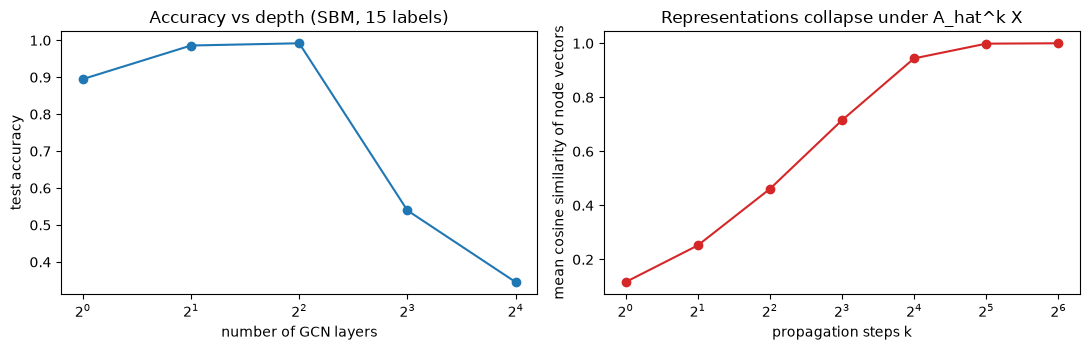

accuracy by depth: {1: 0.895, 2: 0.986, 4: 0.992, 8: 0.539, 16: 0.345}
mean cosine similarity: {0: 0.012, 1: 0.116, 2: 0.252, 4: 0.461, 8: 0.715, 16: 0.944, 32: 0.999, 64: 1.0}


In [13]:
depth_rows = {}
tr, te = few_label_split(y_sbm, 5, seed=0)
for depth in [1, 2, 4, 8, 16]:
    accs = [train_node_classifier(GCN(16, 32, 3, n_layers=depth, dropout=0.2), X_t, A_hat, y_sbm, torch.tensor(tr), torch.tensor(te), seed=s)
            for s in range(3)]
    depth_rows[depth] = np.mean(accs)

def mean_cosine(H):
    Hn = F.normalize(H, dim=1); S = Hn @ Hn.T
    return ((S.sum() - len(H)) / (len(H) * (len(H) - 1))).item()   # average over distinct pairs

cos = {}
H = X_t.clone()
for k in range(0, 65):
    if k in (0, 1, 2, 4, 8, 16, 32, 64):
        cos[k] = mean_cosine(H)
    H = A_hat @ H

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(list(depth_rows), list(depth_rows.values()), "o-"); ax[0].set_xscale("log", base=2)
ax[0].set_xlabel("number of GCN layers"); ax[0].set_ylabel("test accuracy"); ax[0].set_title("Accuracy vs depth (SBM, 15 labels)")
ax[1].plot(list(cos)[1:], list(cos.values())[1:], "o-", c="tab:red"); ax[1].set_xscale("log", base=2)
ax[1].set_xlabel("propagation steps k"); ax[1].set_ylabel("mean cosine similarity of node vectors"); ax[1].set_title("Representations collapse under A_hat^k X")
plt.tight_layout(); plt.show()
print("accuracy by depth:", {k: round(float(v), 3) for k, v in depth_rows.items()})
print("mean cosine similarity:", {k: round(v, 3) for k, v in cos.items()})

**What just happened?** Two to four layers work best here; at 8 layers accuracy drops to about 54% and at 16 layers to chance level (about 1/3). The right panel shows why: after a few dozen propagation steps nearly all node vectors point in the same direction (mean cosine similarity close to 1), so a classifier has nothing left to separate. Remedies: residual/skip connections, jumping-knowledge (concatenate all layers, as our graph classifier did), PairNorm, DropEdge, or decoupling propagation from depth (APPNP, SGC).

### 8.1 Mini-batching and neighbour sampling for big graphs

> 💬 **In plain English:** in a huge graph, a node's friends-of-friends can be millions of nodes. GraphSAGE-style training only samples a handful of neighbours per hop, so each mini-batch stays small.

With $L$ layers, a node's prediction depends on its whole $L$-hop neighbourhood, which in real graphs grows explosively because of hubs ("neighbourhood explosion"). **Neighbour sampling** (GraphSAGE) keeps at most $f_\ell$ random neighbours per node at hop $\ell$, bounding the computation per target node by $\prod_\ell f_\ell$. Related ideas: layer-wise sampling (FastGCN), subgraph sampling (Cluster-GCN, GraphSAINT), and historical embeddings.

In [14]:
big = nx.barabasi_albert_graph(20000, 3, seed=SEED)                # 20k nodes with hubs, ~60k edges
nbrs_big = {v: list(big.neighbors(v)) for v in big.nodes}
r = np.random.default_rng(SEED)
targets = r.choice(big.number_of_nodes(), 64, replace=False)

def full_khop(targets, hops):
    frontier, seen = set(map(int, targets)), set(map(int, targets))
    for _ in range(hops):
        frontier = {u for v in frontier for u in nbrs_big[v]} - seen
        seen |= frontier
    return len(seen)

def sampled_khop(targets, fanouts):
    frontier, seen = set(map(int, targets)), set(map(int, targets))
    for f in fanouts:
        nxt = set()
        for v in frontier:
            nb_v = nbrs_big[v]
            nxt.update(r.choice(nb_v, min(f, len(nb_v)), replace=False).tolist())
        frontier = nxt - seen; seen |= nxt
    return len(seen)

fanouts = [10, 5, 3]                                               # typical: fewer samples at deeper hops
rows = {f"{h}-hop": {"full neighbourhood (nodes)": full_khop(targets, h),
                     "sampled, fan-outs 10/5/3 (nodes)": sampled_khop(targets, fanouts[:h]),
                     "upper bound 64 x (1 + 10 + 10*5 + ...)": 64 * (1 + sum(int(np.prod(fanouts[:i + 1])) for i in range(h)))}
        for h in [1, 2, 3]}
print(f"64 target nodes in a {big.number_of_nodes():,}-node graph:")
print(pd.DataFrame(rows).T)

64 target nodes in a 20,000-node graph:
       full neighbourhood (nodes)  sampled, fan-outs 10/5/3 (nodes)  \
1-hop                         500                               365   
2-hop                        6173                              1398   
3-hop                       18408                              3382   

       upper bound 64 x (1 + 10 + 10*5 + ...)  
1-hop                                     704  
2-hop                                    3904  
3-hop                                   13504  


**What just happened?** For just 64 target nodes, the exact 3-hop neighbourhood already covers most of the 20,000-node graph (hubs connect everything). With sampled fan-outs the mini-batch is several times smaller, and, more importantly, its size has an upper bound that depends only on the batch size and the fan-outs, not on the size of the graph. When the graph grows to billions of edges the exact neighbourhoods keep growing while the sampled ones do not; this is what makes GNN training feasible at that scale (e.g. PinSage at Pinterest).

### 8.2 Optional: the same GCN in PyTorch Geometric

PyTorch Geometric (PyG) provides sparse message passing, hundreds of layers and datasets. It is **optional** here; the cell skips cleanly if it is not installed.

In [15]:
try:
    import torch_geometric
    from torch_geometric.nn import GCNConv
    from torch_geometric.utils import from_networkx

    class PyGGCN(nn.Module):
        def __init__(self):
            super().__init__()
            self.c1, self.c2 = GCNConv(16, 32), GCNConv(32, 3)
        def forward(self, x, edge_index):
            return self.c2(F.dropout(F.relu(self.c1(F.dropout(x, 0.5, self.training), edge_index)), 0.5, self.training), edge_index)

    edge_index = from_networkx(G).edge_index                      # sparse 2 x E edge list (both directions)
    tr, te = few_label_split(y_sbm, 5, seed=0)
    acc_pyg = train_node_classifier(PyGGCN(), X_t, edge_index, y_sbm, torch.tensor(tr), torch.tensor(te), seed=0)
    print(f"PyTorch Geometric {torch_geometric.__version__}: GCN test accuracy {acc_pyg:.3f}")
except ImportError:
    print("PyTorch Geometric is not installed: skipping this optional cell (the from-scratch versions above cover the lesson).")

PyTorch Geometric is not installed: skipping this optional cell (the from-scratch versions above cover the lesson).


## 9. How this connects to modern AI

> 💬 **In plain English:** graphs are everywhere data has relationships, and the same message-passing idea also sits inside Transformers.

| What you built | Where it is used |
|---|---|
| Node embeddings (DeepWalk/node2vec) | candidate generation in recommender systems, fraud and bot detection, entity resolution |
| GCN / GraphSAGE / GAT | traffic ETA prediction (DeepMind with Google Maps), PinSage recommendations at Pinterest, molecular property prediction, chip placement |
| Link prediction with honest splits | "people you may know", drug repurposing, **knowledge-graph completion** for retrieval systems ([`08_LLM/09_knowledge_graphs/01_knowledge_graphs.ipynb`](../08_LLM/09_knowledge_graphs/01_knowledge_graphs.ipynb)) |
| Graph classification, WL expressiveness | molecules and materials (e.g. GNoME at DeepMind used GNNs to propose new stable crystals), program analysis |
| Attention over neighbours (GAT) | a **Transformer** is a GAT on the *complete* graph of tokens; graph Transformers add positional encodings from the Laplacian or random walks |
| Spectral methods, PageRank | graph databases and analytics ([`13_Databases/07_graph_databases/01_graph_databases.ipynb`](../13_Databases/07_graph_databases/01_graph_databases.ipynb)); GraphRAG systems cluster entity graphs into communities before summarising them for LLMs |

## 10. Recap

- Graphs are matrices: adjacency $A$, degrees $D$, features $X$; real systems store them sparsely.
- **Classic features** (degree, PageRank, clustering, centralities) capture structural roles but not communities.
- **Spectral embedding:** small-eigenvalue eigenvectors of $L_{sym}$ separate communities; the eigengap counts them; the Fiedler vector bisects the graph.
- **DeepWalk/node2vec:** random walks + skip-gram with negative sampling; $p,q$ trade BFS-like vs DFS-like exploration; transductive.
- **GCN** $\hat A\,\sigma(\hat AXW_0)W_1$; **GraphSAGE** separates self and mean-neighbour terms and supports sampling (inductive); **GAT** learns neighbour weights.
- **Link prediction:** split edges first, use only the training graph, sample negatives, report AUC; leakage inflates every method, GNNs most.
- **Graph classification:** pool node vectors; **sum** is more expressive than mean; message-passing GNNs are at most as powerful as **1-WL**.
- **Over-smoothing** limits depth; **neighbour sampling** bounds the cost on big graphs.

## Practice problems

**1. (Easy, conceptual)** Why does the GCN add self-loops ($\tilde A = A + I$) before normalising? What would a layer compute for a node without them?

<details><summary>Show solution</summary>

Without self-loops, $h_i'$ depends only on the neighbours, so the node's **own** features are thrown away at every layer (and an isolated node gets a zero vector). Self-loops make each node part of its own neighbourhood. Normalising by $\tilde D^{-1/2}$ on both sides keeps the scale of the aggregated vectors stable regardless of degree (and makes $\hat A$ symmetric with eigenvalues in $(-1, 1]$).
</details>

**2. (Easy, coding)** Show that the matrix $A^2$ counts common neighbours, and write Adamic-Adar as a matrix product. Check both against NetworkX on the karate club.

<details><summary>Show solution</summary>

$(A^2)_{uv} = \sum_w A_{uw}A_{wv}$ counts the nodes $w$ adjacent to both, i.e. paths of length 2. Adamic-Adar weights each such $w$ by $1/\log d_w$: $AA = A\,\operatorname{diag}(1/\log d)\,A$.

```python
import numpy as np, networkx as nx

G = nx.karate_club_graph()
A = nx.to_numpy_array(G, weight=None)
CN = A @ A                               # (A^2)_{uv} = number of common neighbours (paths of length 2)
for u, v in [(0, 33), (0, 1), (5, 6)]:
    assert CN[u, v] == len(list(nx.common_neighbors(G, u, v)))
print("common neighbours of (0, 33):", int(CN[0, 33]))
deg = A.sum(1)
AA = A @ np.diag(1 / np.log(np.maximum(deg, 2))) @ A    # Adamic-Adar as a matrix product (degree-1 nodes cannot be shared neighbours)
ref = {(u, v): s for u, v, s in nx.adamic_adar_index(G, [(0, 33), (2, 8)])}
assert np.isclose(AA[0, 33], ref[(0, 33)]) and np.isclose(AA[2, 8], ref[(2, 8)])
print("Adamic-Adar (0, 33):", round(AA[0, 33], 4))
```
</details>

**3. (Medium, conceptual)** Spectral clustering on a graph gives 4 near-zero eigenvalues of $L_{sym}$ followed by a large gap. What does that tell you? What if the graph has 3 connected components?

<details><summary>Show solution</summary>

About 4 well-separated communities (the eigengap heuristic). For a graph with exactly $c$ connected components, $L$ and $L_{sym}$ have eigenvalue 0 with multiplicity exactly $c$, and the corresponding eigenvectors are (scaled) indicator vectors of the components, so 3 components give exactly 3 zero eigenvalues. Weakly connected communities perturb these zeros into small positive values.
</details>

**4. (Medium, coding)** Implement **SGC** (Simple Graph Convolution): precompute $\hat A^K X$ and train a plain logistic regression. Compare $K = 0, 1, 2, 4$ on the SBM.

<details><summary>Show solution</summary>

```python
import numpy as np, networkx as nx, torch
from sklearn.linear_model import LogisticRegression

# Simple Graph Convolution (Wu et al., 2019): precompute A_hat^K X, then a linear classifier.
G = nx.stochastic_block_model([60, 60, 60], [[0.12, .01, .01], [.01, .12, .01], [.01, .01, .12]], seed=0)
y = np.array([G.nodes[v]["block"] for v in G.nodes])
rng = np.random.default_rng(0)
X = 0.35 * rng.normal(0, 1, (3, 16))[y] + rng.normal(0, 1, (180, 16))
A = nx.to_numpy_array(G) + np.eye(180)
d = A.sum(1); A_hat = A / np.sqrt(np.outer(d, d))
train = np.concatenate([np.where(y == c)[0][:5] for c in range(3)]); test = np.setdiff1d(np.arange(180), train)
for K in [0, 1, 2, 4]:
    XK = np.linalg.matrix_power(A_hat, K) @ X
    acc = LogisticRegression(max_iter=2000).fit(XK[train], y[train]).score(XK[test], y[test])
    print(f"K={K}: accuracy {acc:.3f}")
    if K == 0: acc0 = acc
    if K == 2: acc2 = acc
assert acc2 > acc0 + 0.2
```
$K=0$ is the feature-only baseline; one or two propagation steps help enormously; large $K$ eventually over-smooths. SGC shows that much of the GCN's power comes from propagation, not from the non-linearity.
</details>

**5. (Medium, conceptual)** You are building friend recommendations. Your GNN link predictor has a validation AUC of 0.99 but performs poorly in production. List three possible leakage or evaluation problems.

<details><summary>Show solution</summary>

(1) Validation edges were present in the message-passing graph or in precomputed features (embeddings, degrees, PageRank) at training time. (2) A random edge split instead of a **temporal** split: future links leak into the past, and production must predict links that do not exist yet. (3) Unrealistic negatives: uniformly random non-edges are trivially easy (far apart in the graph), while production candidates are hard negatives (friends of friends); evaluate with ranking metrics (Hits@k, MRR) on realistic candidates. Also: duplicated users/accounts, and evaluating on nodes seen during training only.
</details>

**6. (Hard, coding)** Show that 1-WL (and therefore any message-passing GNN with identical initial features) cannot distinguish different 3-regular graphs with the same number of nodes.

<details><summary>Show solution</summary>

```python
import networkx as nx

def wl_hist(g, iters=3):
    col = {v: 0 for v in g}
    out = []
    for _ in range(iters):
        col = {v: hash((col[v], tuple(sorted(col[u] for u in g[v])))) for v in g}
        out.append(sorted(col.values()))
    return out

# Any two 3-regular graphs with the same number of nodes look identical to 1-WL.
g1 = nx.circular_ladder_graph(4)           # prism-like, 8 nodes, 3-regular
g2 = nx.cubical_graph()                    # the cube, 8 nodes, 3-regular
g3 = nx.random_regular_graph(3, 8, seed=1)
print([nx.is_isomorphic(g1, g) for g in (g2, g3)])
assert wl_hist(g1) == wl_hist(g2) == wl_hist(g3)
print("1-WL cannot tell these 3-regular graphs apart")
```
In a $d$-regular graph every node sees the same multiset of neighbour colours at every round, so colours never split. A GNN needs extra information (node IDs, random features, cycle counts, positional encodings) to separate them.
</details>

**7. (Hard, conceptual)** Explain the connection between a GAT layer and a Transformer self-attention layer. What does a Transformer "lose" compared with a GNN, and how do graph Transformers get it back?

<details><summary>Show solution</summary>

Both compute attention weights between a node/token and others, normalise them with a softmax and take a weighted sum of transformed values. A GAT restricts attention to graph neighbours (a sparse mask); a Transformer attends over all pairs, i.e. a GAT on the complete graph (with dot-product scores and multiple heads). A Transformer therefore loses the graph structure itself: it only knows positions through positional encodings. Graph Transformers restore it with structural/positional encodings (Laplacian eigenvectors, random-walk probabilities, shortest-path distances as attention biases, as in Graphormer) or by mixing local message passing with global attention (GPS).
</details>

## Further reading

- William L. Hamilton, *Graph Representation Learning* (Morgan & Claypool, 2020; free pre-print online), Ch. 2-7.
- Stanford **CS224W: Machine Learning with Graphs** (Jure Leskovec), lecture notes and videos (free online).
- Papers: Perozzi et al. (2014) DeepWalk; Grover & Leskovec (2016) node2vec; Kipf & Welling (2017) GCN and (2016) graph auto-encoders; Hamilton et al. (2017) GraphSAGE; Veličković et al. (2018) GAT; Xu et al. (2019) "How Powerful are Graph Neural Networks?" (GIN, WL); Li, Han & Wu (2018) on over-smoothing; von Luxburg (2007) "A Tutorial on Spectral Clustering".
- Ulrike von Luxburg's tutorial and Zachary (1977) "An Information Flow Model for Conflict and Fission in Small Groups" (the karate club).

## Next notebook

This completes the hands-on companions to `01`-`07`. Good next steps: [`13_Databases/07_graph_databases/01_graph_databases.ipynb`](../13_Databases/07_graph_databases/01_graph_databases.ipynb) (storing and querying graphs at scale) or [`08_LLM/09_knowledge_graphs/01_knowledge_graphs.ipynb`](../08_LLM/09_knowledge_graphs/01_knowledge_graphs.ipynb) (graphs + LLMs), then continue the module with [`08_model_compression.ipynb`](08_model_compression.ipynb).